# Week5_ex3_analysis - Phase-A Current with the Mover Held Fixed: Force vs Current

![Week5_ex3 result](Images/Week5_ex3_result_image.png)

Maxwell 2D (40 mm depth), Magnetostatic. A 10-pole NdFe35 array (20 x 5 mm magnets, 6 mm gaps, magnetized along ±y) sits on a 15 mm steel_1008 plate. Above a 1 mm air gap are three 100-turn coils (5 x 15 mm sides) around 6 mm slots, but the stator "yoke" and slots are air. Only phase A carries current, and `t_sample` is swept over one 10 Hz period in 21 steps instead of a real time axis. The mover never moves.

With the mover fixed and no iron on the stator side, the force on the coils should just follow the phase-A current: a fixed force constant times i_a, plus a much smaller i_a² term from the coil pulling on its own image in the steel plate. This is a short check with no hypotheses. The CSV was known before this was written, so nothing below is a blind prediction.

$$i_a(t)=I_{rated}\cos(2\pi f t+\theta_0),\quad I_{rated}=\frac{J\,A_{coil}}{N}=\frac{3\cdot 75}{100}=2.25\ \mathrm{A},\qquad \mathbf{F}(t)=\mathbf{K}\,i_a(t)+\mathbf{k}_2\,i_a(t)^2$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Time-sweep results exported by the original notebook
df = pd.read_csv("Week5_ex3_time_sweep_result.csv")
t = df["Time [ms]"].values * 1e-3
i_csv = df["current_a [A]"].values
Fx = df["Force_x [N]"].values
Fy = df["Force_y [N]"].values

# 2. Control law from the original notebook's design variables
J, A_coil, N = 3, 5 * 15, 100
I_rated = J * A_coil / N
theta0 = np.pi / 2
f = 10
i_law = I_rated * np.cos(2 * np.pi * f * t + theta0)

pd.DataFrame({
    "quantity": ["I_rated from J*A/N [A]", "peak |current_a| in CSV [A]", "CSV peak / I_rated",
                 "max deviation from control law [A]"],
    "value": [I_rated, np.abs(i_csv).max(), np.abs(i_csv).max() / I_rated,
              np.abs(i_csv - i_law).max()],
})

,quantity,value
0,I_rated from J*A/N [A],2.250000e+00
1,peak |current_a| in CSV [A],2.250000e+00
2,CSV peak / I_rated,1.000000e+00
3,max deviation from control law [A],5.773160e-15


The exported current follows the control law exactly: zeros at 0 / 50 / 100 ms, peaks of ±2.25 A at 25 and 75 ms, with the right signs. An earlier export stored this column in mA, because `get_solution_data().data_real()` returns values in the report's display unit unless `convert_to_SI=True` is passed. The original notebook now passes it, and the force constant below still gives an independent check that the solver used 2.25 A: with 2.25 kA the force would be a thousand times larger than the coil can produce in this field.

![Week5_ex3 phase currents](Images/Week5_ex3_current_plot.png)

The original current plot shows the same thing: only phase A is active, as a clean cosine starting at zero.

In [2]:
# 3. Least-squares fit F = k1*i + k2*i^2 + c0 for both components
i_a = i_csv
X = np.column_stack([i_a, i_a**2, np.ones_like(i_a)])
coef_x, *_ = np.linalg.lstsq(X, Fx, rcond=None)
coef_y, *_ = np.linalg.lstsq(X, Fy, rcond=None)

fit = pd.DataFrame(
    [coef_x, coef_y],
    index=["Force_x (thrust)", "Force_y (normal)"],
    columns=["k1 [N/A]", "k2 [N/A^2]", "c0 [N]"],
)
fit["max residual [N]"] = [np.abs(Fx - X @ coef_x).max(), np.abs(Fy - X @ coef_y).max()]
fit["peak |F| [N]"] = [np.abs(Fx).max(), np.abs(Fy).max()]
fit

,k1 [N/A],k2 [N/A^2],c0 [N],max residual [N],peak |F| [N]
Force_x (thrust),-0.002748,9.694808e-07,-0.069953,2.453183e-07,0.076132
Force_y (normal),-0.859460,-1.249221e-03,0.007002,4.151511e-07,1.934463


![Week5_ex3 force vs time](Images/Week5_ex3_force_plot.png)

The original force plot shows Force_y swinging with the current and Force_x sitting flat just below zero. What it can't show is how exact that is: once the fit separates the terms, both components are linear in i_a to within 4e-7 N, with a small i_a² part and a constant offset.

Three things come out of the fit:

- **Almost all of the force is normal (y), not thrust (x).** The thrust constant is 0.3% of the normal one. That's a statement about where coil A sits, checked below.
- **The i_a² term in Force_y is negative (toward the magnets).** With an air stator the only thing that can produce it is the steel plate: the coil is attracted to its own image current in the plate. It's 0.3% of the linear part at full current.
- **The constant offset (-0.070 N in x, +0.007 N in y) shouldn't be there.** At i_a = 0 the coils are copper and air, μr ≈ 1, so the field of the magnets can't push on them. It's about 3.6% of the peak normal force and doesn't change with the current, so it reads as a numerical offset of the virtual-force calculation on non-magnetic objects, not physics. It isn't chased here.

In [3]:
# 4. 2D charge model of the magnet array, coil A position from the original notebook's geometry
#    (all lengths in mm). Each magnet = surface charge +-M on its top face; the steel plate is treated as an
#    infinitely permeable plane at y = 7.5 mm, so the bottom-face charge cancels against its own image and the
#    top-face charge gets an opposite image mirrored below the plate surface.
#    NdFe35: mu_r and Hc read once from the AEDT material library; Hc is the value the notebook sets.
mu0 = 4e-7 * np.pi
mu_r, Hc = 1.0997785406, 890000
M = mu_r * Hc

pitch, m_w = 26, 20
x0 = -127                                   # array centered: -(10*20 + 9*6)/2
magnets = []
for k in range(10):
    x1 = x0 + k * pitch
    sign = -1 if k % 2 == 0 else +1          # magnet_1 copies are S-up, magnet_2 copies are N-up
    magnets.append((x1, x1 + m_w, sign))
y_top, y_img = 12.5, 2.5

def B_field(x, y):
    bx = np.zeros_like(x, dtype=float)
    by = np.zeros_like(x, dtype=float)
    for x1, x2, s in magnets:
        for y0, q in ((y_top, 1), (y_img, -1)):
            dy = y - y0
            c = s * q * M / (2 * np.pi)
            by += c * (np.arctan((x - x1) / dy) - np.arctan((x - x2) / dy))
            bx += c * 0.5 * np.log(((x - x1)**2 + dy**2) / ((x - x2)**2 + dy**2))
    return mu0 * bx, mu0 * by

def side_mean(xa, xb, ya=13.5, yb=28.5):
    X, Y = np.meshgrid(np.linspace(xa, xb, 61), np.linspace(ya, yb, 181))
    bx, by = B_field(X, Y)
    return bx.mean(), by.mean()

# Coil A sides after both moves in the original notebook: x = -47..-42 and -36..-31 mm, y = 13.5..28.5 mm.
# Slot A is centered at x = -39 mm, the center of the N-up magnet at -49..-29 mm.
left, right = side_mean(-47, -42), side_mean(-36, -31)
L_depth = 0.040
K_y_model = N * L_depth * abs(left[0] - right[0])
K_x_model = N * L_depth * abs(right[1] - left[1])

pd.DataFrame({
    "quantity": ["mean Bx under left side [T]", "mean Bx under right side [T]",
                 "mean By under left side [T]", "mean By under right side [T]",
                 "|K_y| model [N/A]", "|K_y| FEM [N/A]", "FEM / model - 1 [%]",
                 "|K_x| model [N/A]", "|K_x| FEM [N/A]"],
    "value": [left[0], right[0], left[1], right[1],
              K_y_model, abs(coef_y[0]), (abs(coef_y[0]) / K_y_model - 1) * 100,
              K_x_model, abs(coef_x[0])],
}).round(5)

,quantity,value
0,mean Bx under left side [T],-0.11562
1,mean Bx under right side [T],0.11417
2,mean By under left side [T],0.17124
3,mean By under right side [T],0.17069
4,|K_y| model [N/A],0.91917
5,|K_y| FEM [N/A],0.85946
6,FEM / model - 1 [%],-6.49567
7,|K_x| model [N/A],0.00218
8,|K_x| FEM [N/A],0.00275


Slot A sits exactly over the center of an N-up magnet, so the two sides of coil A are mirror images of each other about that magnet. The vertical field B_y is the same under both sides, and since the two sides carry opposite currents, their thrust cancels. The horizontal field B_x flips sign between the sides, so the normal forces add. Phase A is sitting on its d-axis, which is also why the control angle θ0 = π/2 puts its current at zero at t = 0. With all three phases on, the thrust would come from B and C.

The charge model gives |K_y| = 0.92 N/A against 0.86 N/A from the FEM, so the FEM comes out 6.5% below the model. For a model that treats a 15 mm plate as an infinitely permeable plane and ignores the magnets' own μr, that's as close as it should get. It also confirms the unit: with the CSV current taken as amps, the FEM force constant would be 0.86 mN/A, a thousand times below this estimate.

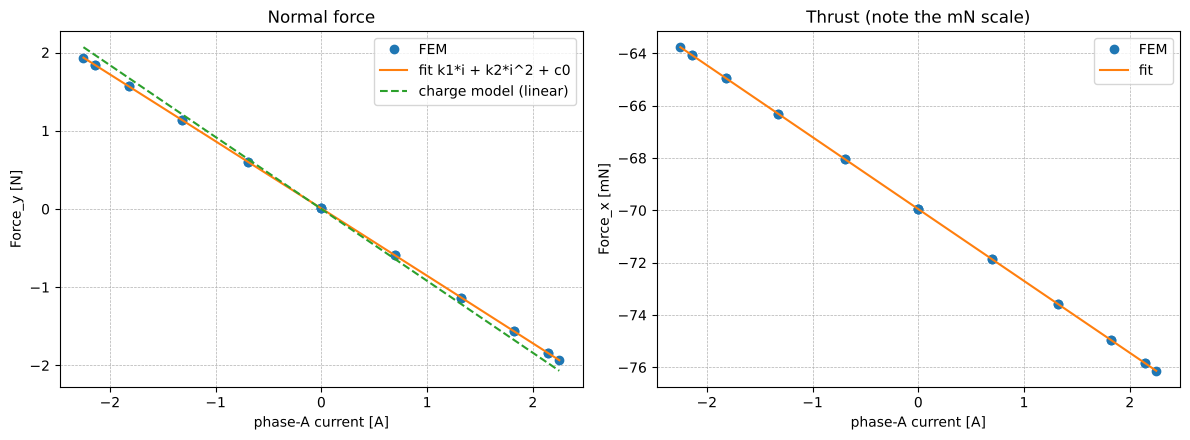

In [4]:
# 5. Force vs phase-A current with the fitted curves
i_line = np.linspace(-I_rated, I_rated, 200)
X_line = np.column_stack([i_line, i_line**2, np.ones_like(i_line)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(i_a, Fy, "o", label="FEM")
axes[0].plot(i_line, X_line @ coef_y, "-", label="fit k1*i + k2*i^2 + c0")
axes[0].plot(i_line, -K_y_model * i_line, "--", label="charge model (linear)")
axes[0].set_xlabel("phase-A current [A]")
axes[0].set_ylabel("Force_y [N]")
axes[0].set_title("Normal force")
axes[0].legend()
axes[0].grid(True, linestyle="--", linewidth=0.5)

axes[1].plot(i_a, Fx * 1e3, "o", label="FEM")
axes[1].plot(i_line, (X_line @ coef_x) * 1e3, "-", label="fit")
axes[1].set_xlabel("phase-A current [A]")
axes[1].set_ylabel("Force_x [mN]")
axes[1].set_title("Thrust (note the mN scale)")
axes[1].legend()
axes[1].grid(True, linestyle="--", linewidth=0.5)

fig.tight_layout()
plt.savefig("Images/Week5_ex3_force_vs_current.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

With the mover held still and an air stator, the force on the coils is a fixed vector times the phase-A current, and the sweep shows exactly that: both components are linear in i_a to within 4e-7 N across all 21 points. The force is almost entirely normal (K_y = -0.86 N/A, thrust constant 0.3% of that), because coil A's slot sits right over the center of a magnet, which is phase A's d-axis position. A 2D charge model of the magnet array on an ideal iron plane gives 0.92 N/A for the same position, with the FEM 6.5% below it, which is reasonable for that model.

Two small extra terms show up in the fit. A negative i_a² term (0.3% of the linear part at full current) is the coil being pulled toward the steel plate by its own image. A constant offset of -0.070 N in x and +0.007 N in y appears at zero current, where non-magnetic coils can't feel any force, so it's left as a numerical offset of the virtual-force calculation.

One problem turned up in the exported data rather than the physics: the first export stored the current column in mA, because `data_real()` returns the report's display unit by default. The AEDT report itself showed 2.25 A, and the force constant confirmed independently that the solver used 2.25 A. The original notebook now exports with `convert_to_SI=True`, and nothing else needs further analysis.